# 01 · Canal endémico de epiCo y variable objetivo

Este cuaderno muestra el canal endémico con el que se define la variable objetivo del pronóstico y la frecuencia de la zona epidémica en cada municipio piloto.

- **Datos.** Producto del canal `data/processed/epidemiology/pilot_weekly_channel.parquet` (F1): conteos agregados por municipio y semana, sin registros individuales. Se obtiene con `dvc pull`; el código comprueba su md5 contra `datos.version_dvc_canal` de `configs/forecasting.yaml`.
- **Código.** `src/epidemiology/channel_epico.py` (fórmula del canal) y `src/forecasting/dataset.py` (lectura verificada del producto).
- **Alcance.** Solo lee: no escribe en `data/` ni en `reports/` y no usa MLflow.

In [1]:
import os
import sys
from pathlib import Path

# Rutas relativas a la raíz del repositorio, tanto si el cuaderno se abre desde notebooks/ como desde la raíz.
ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "forecasting.yaml").is_file():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "forecasting.yaml").is_file():
    raise RuntimeError("El cuaderno se ejecuta desde la raíz del repositorio o desde notebooks/.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src.forecasting.config import load_config
from src.forecasting.dataset import load_channel_product

config = load_config()   # configs/forecasting.yaml, validado con Pydantic
canal = load_channel_product(config.datos.canal, expected_md5=config.datos.version_dvc_canal).to_pandas()
canal["week_start"] = pd.to_datetime(canal["week_start"])
nombres = canal.groupby("municipality_code")["municipality"].first()

print(f"Filas: {len(canal):,} ({canal['municipality_code'].nunique()} municipios × "
      f"{canal['week_start'].nunique()} semanas, {canal['week_start'].min():%Y-%m-%d} a {canal['week_start'].max():%Y-%m-%d})")
print(f"Semanas elegibles del canal: {int(canal['channel_eligible'].sum()):,}")
print(f"Parámetros del canal: n = {config.canal.n} años, desplazamiento = {config.canal.desplazamiento}, "
      f"cuantil t = {config.canal.cuantil_t}")

Filas: 5,952 (6 municipios × 992 semanas, 2007-01-01 a 2025-12-29)
Semanas elegibles del canal: 4,380
Parámetros del canal: n = 5 años, desplazamiento = 1, cuantil t = 0.025


## El canal y sus zonas

Para cada municipio y semana, el canal de epiCo (método geométrico) usa los conteos de la misma semana ordinal en los cinco años anteriores:

- **central** (`epico_central`) = exp(media de log(x + 1)) − 1, la media geométrica con desplazamiento 1;
- **U1e** (`epico_upper`) = central · exp(|t(0,025; 4)| · sd(log(x + 1)) / √5), el límite superior del intervalo t.

Con el conteo C de la semana: **seguridad** si C ≤ central, **alerta** si central < C ≤ U1e y **epidemia** si C > U1e (`channel_zone`). La variable objetivo es `target_u1e` = 1[C > U1e]: el modelo estima la probabilidad de zona epidémica en la semana t + 8. Las semanas de 2007 a 2011 (sin cinco años de referencia) y la semana parcial 2025-12-29 no son elegibles.

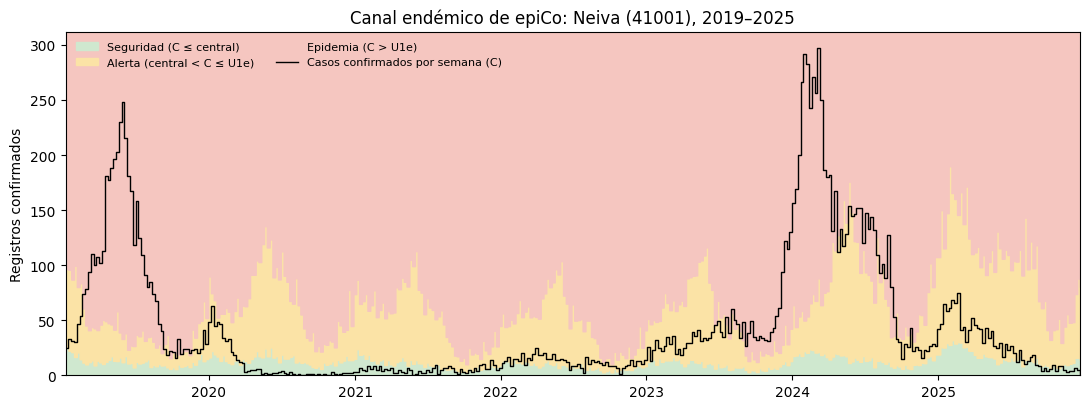

In [3]:
CODIGO = "41001"   # Neiva; cualquier código piloto sirve
DESDE = "2019-01-01"

serie = canal[(canal["municipality_code"] == CODIGO) & canal["channel_eligible"] & (canal["week_start"] >= DESDE)]
x, casos = serie["week_start"], serie["confirmed_records_screening"]
techo = 1.05 * max(casos.max(), serie["epico_upper"].max())

fig, ax = plt.subplots(figsize=(11, 4.2), dpi=100)
ax.fill_between(x, 0, serie["epico_central"], step="post", color="#cfe8cf", label="Seguridad (C ≤ central)")
ax.fill_between(x, serie["epico_central"], serie["epico_upper"], step="post", color="#fbe3a6",
                label="Alerta (central < C ≤ U1e)")
ax.fill_between(x, serie["epico_upper"], techo, step="post", color="#f5c6c0", label="Epidemia (C > U1e)")
ax.step(x, casos, where="post", color="black", linewidth=1, label="Casos confirmados por semana (C)")
ax.set_ylim(0, techo)
ax.set_xlim(x.min(), x.max())
ax.set_ylabel("Registros confirmados")
ax.set_title(f"Canal endémico de epiCo: {nombres[CODIGO]} ({CODIGO}), {DESDE[:4]}–2025")
ax.legend(loc="upper left", fontsize=8, ncol=2, frameon=False)
fig.tight_layout()
plt.show()

In [4]:
zonas_por_anio = pd.crosstab(serie["week_start"].dt.year, serie["channel_zone"])[["seguridad", "alerta", "epidemia"]]
zonas_por_anio.index.name = "Año"
zonas_por_anio.columns.name = f"Semanas por zona, {nombres[CODIGO]}"
zonas_por_anio

"Semanas por zona, Neiva",seguridad,alerta,epidemia
Año,,,
2019,1,16,35
2020,42,10,0
2021,42,10,0
2022,10,42,0
2023,1,28,23
2024,0,21,32
2025,18,33,0


## Prevalencia de la zona epidémica por municipio

Fracción de semanas elegibles con `target_u1e` = 1, en todo el periodo elegible y en cada partición de `configs/forecasting.yaml` (por año de la semana). Es una descripción de la serie observada, no de las filas de entrenamiento ni de evaluación: estas últimas se definen por la semana objetivo t + 8 y exigen 12 semanas elegibles antes de t.

In [5]:
v = config.validacion
elegibles = canal[canal["channel_eligible"]].copy()
anio = elegibles["week_start"].dt.year
periodos = {
    f"{v.primer_anio_entrenamiento}–{v.desarrollo[0] - 1}": (anio < v.desarrollo[0]),
    f"Desarrollo {v.desarrollo[0]}–{v.desarrollo[1]}": anio.between(*v.desarrollo),
    f"Prueba {v.prueba[0]}–{v.prueba[1]}": anio.between(*v.prueba),
}

filas = []
for codigo, grupo in elegibles.groupby("municipality_code"):
    fila = {"Código": codigo, "Municipio": nombres[codigo], "Semanas elegibles": len(grupo),
            "Semanas en epidemia": int(grupo["target_u1e"].sum()), "Prevalencia total": grupo["target_u1e"].mean()}
    for nombre, mascara in periodos.items():
        fila[nombre] = grupo.loc[mascara[grupo.index], "target_u1e"].mean()
    filas.append(fila)
total = {"Código": "Total", "Municipio": "Seis pilotos", "Semanas elegibles": len(elegibles),
         "Semanas en epidemia": int(elegibles["target_u1e"].sum()), "Prevalencia total": elegibles["target_u1e"].mean()}
total.update({nombre: elegibles.loc[mascara, "target_u1e"].mean() for nombre, mascara in periodos.items()})
prevalencia = pd.DataFrame(filas + [total]).set_index("Código")
for columna in ["Prevalencia total", *periodos]:
    prevalencia[columna] = prevalencia[columna].map("{:.1%}".format)
prevalencia

,Municipio,Semanas elegibles,Semanas en epidemia,Prevalencia total,2012–2018,Desarrollo 2019–2022,Prueba 2023–2025
Código,,,,,,,
08001,Barranquilla,730,171,23.4%,12.6%,37.5%,30.1%
08758,Soledad,730,204,27.9%,18.0%,41.8%,32.7%
41001,Neiva,730,152,20.8%,16.9%,16.8%,35.3%
50001,Villavicencio,730,165,22.6%,15.6%,26.4%,34.0%
54001,San José de Cúcuta,730,129,17.7%,9.6%,21.2%,32.1%
76001,Cali,730,124,17.0%,10.4%,9.6%,42.3%
Total,Seis pilotos,4380,945,21.6%,13.8%,25.6%,34.4%


La zona epidémica no es un evento raro en estos municipios: ocupa una fracción grande de las semanas y varía entre municipios y periodos. Por eso el pronóstico se compara con B2 (la probabilidad de zona epidémica en t + 8 según la zona actual del canal) y con B1 (la estacionalidad de la semana objetivo), y no con una tasa base única.